# Comparison of Structural Materials Neutronic Performanca

In [1]:
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import structural_material_analysis as sma

/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/material.py:1512: UserWarning: Warning: sum of fractions do not add to 1, void fraction set to 0.09999999999999987
  warnings.warn(msg)


## General info

In [2]:
fusion_power = 525e6  # units Watts
energy_per_fusion_reaction = 17.6e6  # units eV
eV_to_Joules = 1.60218e-19  # multiplication factor to convert eV to Joules
number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Joules)
print('Number of neutrons per second', number_of_neutrons_per_second, '\n')

fw_volume = 2234489.71 # units cm^3
fw_surface = 4468977.87 # units cm^2
vessel_inner_volume = 3376578.27 # units cm^3
vessel_inner_surface = 4502100.88 # units cm^2
vessel_outer_volume = 6961366.51 # units cm^3
vessel_outer_surface = 4640897.08 # units cm^2

Number of neutrons per second 1.8618098749544654e+20 



In [3]:
inconel718 = sma.materials.inconel718
ss316l = sma.materials.ss316l
silicon_carbide = sma.materials.silicon_carbide
vcrti = sma.materials.vcrti
ods_eurofer = sma.materials.ods_eurofer
ht9 = sma.materials.ht9

In [4]:
sp_inconel718 = openmc.StatePoint(f"../1_neutronics/results/inconel718.h5")
sp_ss316l = openmc.StatePoint(f"../1_neutronics/results/ss316l.h5")
sp_silicon_carbide = openmc.StatePoint(f"../1_neutronics/results/silicon_carbide.h5")
sp_vcrti = openmc.StatePoint(f"../1_neutronics/results/vcrti.h5")
sp_ods_eurofer = openmc.StatePoint(f"../1_neutronics/results/ods_eurofer.h5")
sp_ht9 = openmc.StatePoint(f"../1_neutronics/results/ht9.h5")

### TBR

In [5]:
inconel718_tbr = sma.analysis.extract_tbr_contributions(sp_inconel718, "TBR")
ss316l_tbr = sma.analysis.extract_tbr_contributions(sp_ss316l, "TBR")
silicon_carbide_tbr = sma.analysis.extract_tbr_contributions(sp_silicon_carbide, "TBR")
vcrti_tbr = sma.analysis.extract_tbr_contributions(sp_vcrti, "TBR")
ods_eurofer_tbr = sma.analysis.extract_tbr_contributions(sp_ods_eurofer, "TBR")
ht9_tbr = sma.analysis.extract_tbr_contributions(sp_ht9, "TBR")

### EM

In [6]:
E_source = 14.1
em_tally = sp_inconel718.get_tally(name='heating_full')
inconel718_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_ss316l.get_tally(name='heating_full')
ss316l_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_silicon_carbide.get_tally(name='heating_full')
silicon_carbide_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_vcrti.get_tally(name='heating_full')
vcrti_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_ods_eurofer.get_tally(name='heating_full')
ods_eurofer_em = em_tally.mean.sum() / 1e6 / E_source

em_tally = sp_ht9.get_tally(name='heating_full')
ht9_em = em_tally.mean.sum() / 1e6 / E_source


### DPA

In [7]:
dpa_tally_str1 = sp_inconel718.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['inconel718']
inconel718_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,  
    atomic_mass_u=props["mass_u"],                
    density_g_per_cm3=inconel718.density,  
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],  
)

dpa_tally_str1 = sp_ss316l.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['ss316l']
ss316l_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=ss316l.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_silicon_carbide.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['silicon_carbide']
silicon_carbide_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=silicon_carbide.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_vcrti.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['vcrti']
vcrti_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=vcrti.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_ods_eurofer.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['ods_eurofer']
ods_eurofer_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=ods_eurofer.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

dpa_tally_str1 = sp_ht9.get_tally(name="dpa_str1")
df_str1 = dpa_tally_str1.get_pandas_dataframe()
props = sma.materials.properties.structural['ht9']
ht9_dpa = sma.analysis.compute_dpa_from_tally(
    df=df_str1,
    number_of_neutrons_per_second=number_of_neutrons_per_second,
    atomic_mass_u=props["mass_u"],
    density_g_per_cm3=ht9.density,
    volume_cm3=vessel_inner_volume,
    Ed_eV=props["Ed"],
)

### Absorption rate

In [8]:
tally_abs = sp_inconel718.get_tally(name="absorption_str1")
inconel718_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_ss316l.get_tally(name="absorption_str1")
ss316l_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_silicon_carbide.get_tally(name="absorption_str1")
silicon_carbide_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_vcrti.get_tally(name="absorption_str1")
vcrti_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_ods_eurofer.get_tally(name="absorption_str1")
ods_eurofer_abs = tally_abs.get_pandas_dataframe()

tally_abs = sp_ht9.get_tally(name="absorption_str1")
ht9_abs = tally_abs.get_pandas_dataframe()


### Power density

In [9]:
inconel718_pd_df = sma.analysis.compute_region_heating(sp_inconel718, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
ss316l_pd_df = sma.analysis.compute_region_heating(sp_ss316l, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
silicon_carbide_pd_df = sma.analysis.compute_region_heating(sp_silicon_carbide, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
vcrti_pd_df = sma.analysis.compute_region_heating(sp_vcrti, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
ods_eurofer_pd_df = sma.analysis.compute_region_heating(sp_ods_eurofer, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)
ht9_pd_df = sma.analysis.compute_region_heating(sp_ht9, 'heating_str1', number_of_neutrons_per_second, vessel_inner_volume)

In [10]:
inconel718_pd = inconel718_pd_df.loc[inconel718_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
ss316l_pd = ss316l_pd_df.loc[ss316l_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
silicon_carbide_pd = silicon_carbide_pd_df.loc[silicon_carbide_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
vcrti_pd = vcrti_pd_df.loc[vcrti_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
ods_eurofer_pd = ods_eurofer_pd_df.loc[ods_eurofer_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]
ht9_pd = ht9_pd_df.loc[ht9_pd_df['Particle'] == 'Total', 'Power Density [MW/m³]'].values[0]

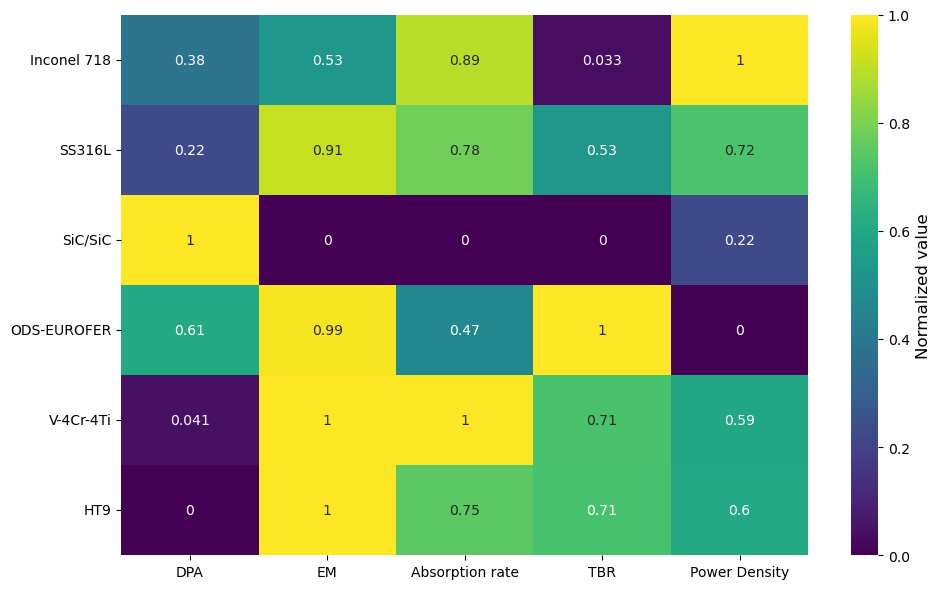

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

data = {
    '': ["Inconel 718", "SS316L", "SiC/SiC", "ODS-EUROFER", "V-4Cr-4Ti", "HT9"],
    'DPA': [inconel718_dpa['DPA'].item(), ss316l_dpa['DPA'].item(), silicon_carbide_dpa['DPA'].item(), vcrti_dpa['DPA'].item(), ods_eurofer_dpa['DPA'].item(), ht9_dpa['DPA'].item()],
    'EM': [inconel718_em, ss316l_em, silicon_carbide_em, vcrti_em, ods_eurofer_em, ht9_em],
    'Absorption rate': [inconel718_abs['mean'].item(), ss316l_abs['mean'].item(), silicon_carbide_abs['mean'].item(), vcrti_abs['mean'].item(), ods_eurofer_abs['mean'].item(), ht9_abs['mean'].item()],
    'TBR': [inconel718_tbr['TBR'].item(), ss316l_tbr['TBR'].item(), silicon_carbide_tbr['TBR'].item(), vcrti_tbr['TBR'].item(), ods_eurofer_tbr['TBR'].item(), ht9_tbr['TBR'].item()],
    'Power Density': [inconel718_pd, ss316l_pd, silicon_carbide_pd, vcrti_pd, ods_eurofer_pd, ht9_pd],
}
df = pd.DataFrame(data).set_index('')

# Normalize values for visual comparison
df_norm = (df - df.min()) / (df.max() - df.min())

# Plot the heatmap
plt.figure(figsize=(10, 6))

ax = sns.heatmap(df_norm, annot=True, cmap="viridis", cbar_kws={'label': 'Normalized value'})
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)
cbar.ax.yaxis.label.set_size(12) 
# plt.title("Normalized comparison of materials across key metrics")
plt.tight_layout()
plt.savefig('norm_comparison.pdf', format='pdf', bbox_inches='tight')

plt.show()


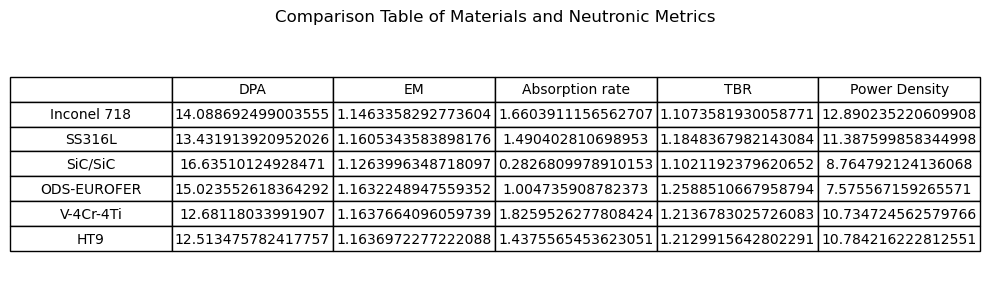

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data)

fig, ax = plt.subplots(figsize=(10, 3)) 
ax.axis('off')  

table = ax.table(cellText=df.values, colLabels=df.columns, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)  

plt.title("Comparison Table of Materials and Neutronic Metrics", pad=20)
plt.tight_layout()
plt.show()
